In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
boats = pd.read_csv('boats.csv')
fx_rates = pd.read_csv('fx_rates.csv')
listings = pd.read_csv('listings.csv', parse_dates=['listing_date'])

In [3]:
boats

,boat_id,manufacturer,model,boat_type,year_built,age_years,length_ft,length_m,beam_ft,hull_material,fuel_type,engine_count
0,FAI53080B89807,Fairhaven,Fairhaven 26 Sundancer,Express Cruiser,1989,36,26.5,8.08,8.7,fiberglass,diesel,1
1,BLU41880U16428,Bluewake,Bluewake 23 Sport,Bowrider,2016,9,23.0,7.01,7.6,fiberglass,gas,1
2,DRI75880U13597,Driftmark,Driftmark 16 SE,Bowrider,2013,12,16.0,4.88,5.2,fiberglass,gas,1
3,NOR13027L07038,Northwind Yachts,Northwind 53 Sedan,Trawler,2007,18,53.0,16.15,17.8,fiberglass,diesel,1
4,SUN35961U21004,Sunmeadow,Sunmeadow 25 LX,Pontoon,2021,4,25.0,7.62,9.5,aluminum,gas,1
...,...,...,...,...,...,...,...,...,...,...,...,...
33450,KEE54221Q13720,Keelson,Keelson 40 Convertible,Sportfish,2013,12,39.5,12.04,12.9,fiberglass,diesel,2
33451,DRI82161F09124,Driftmark,Driftmark 25 BR,Bowrider,2009,16,25.0,7.62,8.2,fiberglass,gas,1
33452,HAL95947B05526,Halyard & Co,Halyard 37,Sailboat,2005,20,37.0,11.28,12.6,fiberglass,diesel,1
33453,PET36630M13492,Petrel,Petrel 42,Catamaran,2013,12,42.5,12.95,22.4,fiberglass,diesel,2


In [4]:
listings

,listing_id,boat_id,seller_id,seller_type,region,listing_date,currency,list_price,engine_hours,condition,n_photos,n_price_drops,final_list_price,days_on_market,status,sale_date,sale_price
0,L0000001,HAL95846G10001,S000001,private,US-GreatLakes,2019-01-01,USD,99999999,NaN,NaN,8,1,99999999,300,withdrawn,NaN,NaN
1,L0000002,TAR98511D02002,S000002,private,US-Northeast,2019-01-01,USD,582900,NaN,excellent,9,0,583000,36,withdrawn,NaN,NaN
2,L0000003,HAL82255O14003,D0118,dealer,US-GreatLakes,2019-01-01,USD,265000,205.0,good,25,1,252000,42,sold,2019-02-12,239500.0
3,L0000004,HAL48694A88004,D0185,dealer,UK,2019-01-01,GBP,29100,1243.0,good,21,2,26200,114,withdrawn,NaN,NaN
4,L0000005,RIV32407V14005,D0295,dealer,US-GreatLakes,2019-01-01,USD,36000,773.0,good,14,0,36000,5,sold,2019-01-06,35800.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38991,L0037714,HAL15543L18418,S018222,private,EU-North,2024-12-31,EUR,176900,1559.0,project,3,0,177000,0,active,NaN,NaN
38992,L0037783,WEX85035V04500,D0450,dealer,EU-Med,2024-12-31,EUR,108000,1830.0,NaN,9,0,110900,0,active,NaN,NaN
38993,L0038086,TAR23600A15458,D0054,dealer,US-Gulf,2024-12-31,USD,95500,887.0,fair,12,0,97900,0,active,NaN,NaN
38994,L0038558,LAR74070J19445,D0098,dealer,UK,2024-12-31,GBP,28700,205.0,good,21,0,28200,0,active,NaN,NaN


In [5]:
listings.isnull().sum()

listing_id              0
boat_id                 0
seller_id               0
seller_type             0
region                  0
listing_date            0
currency              373
list_price              0
engine_hours         4610
condition            8372
n_photos                0
n_price_drops           0
final_list_price        0
days_on_market          0
status                  0
sale_date           12522
sale_price          12522
dtype: int64

In [6]:
listings.describe()

,listing_date,list_price,engine_hours,n_photos,n_price_drops,final_list_price,days_on_market,sale_price
count,38996,3.899600e+04,34386.000000,38996.000000,38996.000000,3.899600e+04,38996.000000,2.647400e+04
mean,2022-02-02 05:56:51.672992256,6.803772e+05,1208.326557,12.019617,1.562647,6.601874e+05,106.346702,2.875833e+05
min,2019-01-01 00:00:00,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00
25%,2020-07-10 00:00:00,4.520000e+04,295.000000,7.000000,0.000000,4.170000e+04,33.000000,4.170000e+04
50%,2022-03-26 00:00:00,1.060000e+05,658.000000,11.000000,1.000000,9.770000e+04,80.000000,9.850000e+04
75%,2023-08-05 00:00:00,2.840000e+05,1347.000000,17.000000,2.000000,2.630000e+05,162.000000,2.697000e+05
max,2024-12-31 00:00:00,1.000000e+08,99999.000000,43.000000,9.000000,1.000000e+08,300.000000,1.226520e+07
std,NaN,6.182012e+06,2993.600866,6.515516,1.701481,6.179923e+06,88.411130,5.980705e+05


In [7]:
listings['listing_id'].nunique()

38846

In [8]:
listings = listings.drop_duplicates(subset='listing_id')

In [9]:
# Clean the placeholder prices and engine hours
listings.loc[listings['list_price'] == 99999999, 'list_price'] = np.nan
listings.loc[listings['final_list_price'] == 99999999, 'final_list_price'] = np.nan
listings.loc[listings['engine_hours'] == 99999, 'engine_hours'] = np.nan

In [10]:
# Merge the currency exchange, fix the currency column missing issue by looking at the region
listings['month'] = listings['listing_date'].apply(lambda x: str(x)[:7])
listings = pd.merge(listings, fx_rates, on='month', how='left')
listings['currency'] = np.where(listings['region'].str.startswith('US'), 'USD', np.where(listings['region'].str.startswith('UK'), 'GBP', np.where(listings['region'].str.startswith('EU'), 'EUR', np.nan)))
listings['ratio'] = np.where(listings['currency'] == 'USD', 1, np.where(listings['currency'] == 'GBP', listings['usd_per_gbp'], np.where(listings['currency'] == 'EUR', listings['usd_per_eur'], np.nan)))
listings[['currency', 'ratio']].isnull().sum()

C:\Users\20122\AppData\Local\Temp\ipykernel_38184\2714560076.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  listings['month'] = listings['listing_date'].apply(lambda x: str(x)[:7])


currency    0
ratio       0
dtype: int64

In [11]:
listings['status'].value_counts()

status
sold         26377
withdrawn    10075
active        2394
Name: count, dtype: int64

In [12]:
listings.loc[listings['status'] == 'withdrawn', 'days_on_market'].describe()

count    10075.000000
mean       151.455285
std        108.596023
min          0.000000
25%         48.000000
50%        128.000000
75%        277.000000
max        300.000000
Name: days_on_market, dtype: float64

Because the ultimate task is to have the hiding model that generates the estimate of the price, those withdrawn and active data doesn't make much use here, for those withdrawn rows, it might be that people changed their mind initially (in this case the price could be close to the fair sale price), or after a period of time when he realized it's hard to trade at his price (in this case the price is higher than fair price).

In [13]:
sold_listings = listings[listings['status'] == 'sold']

In [14]:
sold_listings['sale_price'].describe()

count    2.637700e+04
mean     2.875694e+05
std      5.980680e+05
min      0.000000e+00
25%      4.170000e+04
50%      9.860000e+04
75%      2.694000e+05
max      1.226520e+07
Name: sale_price, dtype: float64

In [15]:
sold_listings[sold_listings['sale_price'].isin([0, 1])]['list_price'].describe()

count    1.320000e+02
mean     3.331045e+05
std      6.602800e+05
min      8.640000e+03
25%      4.362500e+04
50%      9.965000e+04
75%      3.287500e+05
max      5.970000e+06
Name: list_price, dtype: float64

In [16]:
sold_listings[sold_listings['list_price'].isin([0, 1])]['sale_price'].describe()

count    1.880000e+02
mean     8.078564e+05
std      9.165646e+05
min      1.070000e+04
25%      2.272000e+05
50%      5.225000e+05
75%      9.789500e+05
max      6.212800e+06
Name: sale_price, dtype: float64

For those data entries with sale price 0/1, the list price are all normal, which indicates that the sale price isn't normally logged in the dataframe, this is also same for those with list price 0/1 but normal sale prices. But these data are also different from the withdrawn rows because they are actually successfully traded, we further look at the final sale price and listing price to see if their differences are small enough to be safe filling those with listing price.

In [17]:
valid_sale = sold_listings[(sold_listings['sale_price'] > 1) & (sold_listings['list_price'] > 1)]
(valid_sale['list_price'] / valid_sale['sale_price']).describe()

count    25954.000000
mean         1.124105
std          0.089536
min          0.963850
25%          1.056402
50%          1.104670
75%          1.170888
max          1.671063
dtype: float64

In [18]:
sold_listings.loc[sold_listings['list_price'].isin([0, 1]), 'list_price'] = sold_listings['sale_price']
sold_listings.loc[sold_listings['sale_price'].isin([0, 1]), 'sale_price'] = sold_listings['list_price']
sold_listings.loc[sold_listings['list_price'].isnull(), 'list_price'] = sold_listings['sale_price']
sold_listings.loc[sold_listings['sale_price'].isnull(), 'sale_price'] = sold_listings['list_price']

In [19]:
dropping_condition = (sold_listings['list_price'].isnull()) & (sold_listings['sale_price'].isnull())
print(dropping_condition.sum() / len(listings))
sold_listings = sold_listings[~dropping_condition]

0.0


In [20]:
sold_listings['usd_sale_price'] = sold_listings['sale_price'] * sold_listings['ratio']
sold_listings['usd_list_price'] = sold_listings['list_price'] * sold_listings['ratio']

## A1

In [21]:
sold_listings['year'] = sold_listings['listing_date'].dt.year

In [22]:
sold_listings['usd_sale_price'].describe()

count    2.637700e+04
mean     3.012339e+05
std      6.203794e+05
min      2.400000e+03
25%      4.459686e+04
50%      1.034000e+05
75%      2.840000e+05
max      1.226520e+07
Name: usd_sale_price, dtype: float64

In [23]:
sold_listings['usd_list_price'].describe()

count    2.637700e+04
mean     3.346866e+05
std      6.835872e+05
min      2.630000e+03
25%      4.980000e+04
50%      1.166700e+05
75%      3.169000e+05
max      1.370000e+07
Name: usd_list_price, dtype: float64

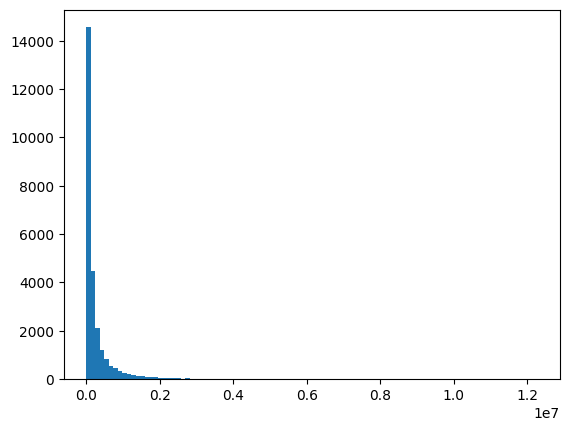

In [24]:
plt.hist(sold_listings['usd_sale_price'], bins=100)
plt.show()

From the distribution we see that the usd_sale_price is quite right-skewed, and because every price data is larger than 0, we take the log of prices to make the distribution normal, which helps us fit the model without being distorted to fit those extreme values.

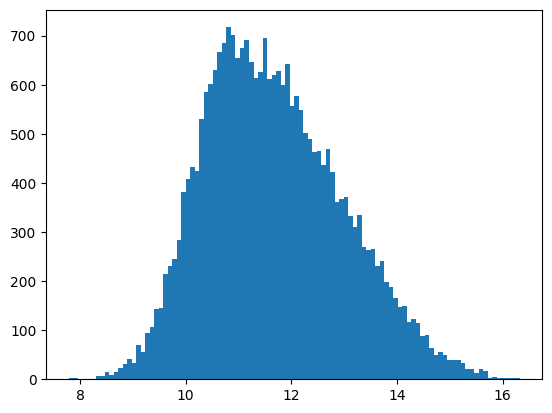

In [25]:
sold_listings['log_usd_sale_price'] = np.log(sold_listings['usd_sale_price'])
sold_listings['log_usd_list_price'] = np.log(sold_listings['usd_list_price'])
plt.hist(sold_listings['log_usd_sale_price'], bins=100)
plt.show()

Skewness for log_usd_sale_price: 0.3988788711671929 Excess kurtosis: -0.22623233735238824


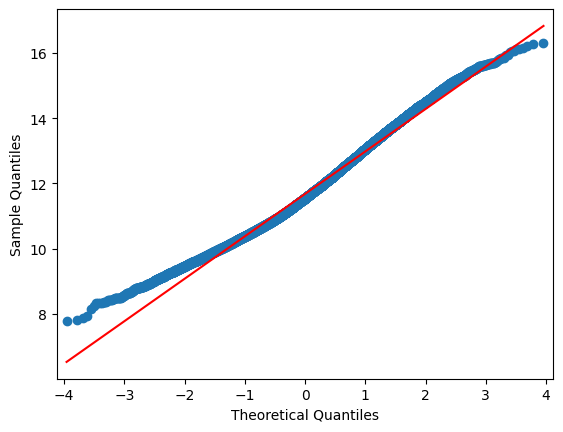

In [26]:
import statsmodels.api as sm
from scipy.stats import skew, kurtosis
sm.qqplot(sold_listings['log_usd_sale_price'], line='s')
print(f"Skewness for log_usd_sale_price: {skew(sold_listings['log_usd_sale_price'])} Excess kurtosis: {kurtosis(sold_listings['log_usd_sale_price'])}")

After taking the log the data looks quite normally distributed and thus can be used for the prediction target, but by transforming we are actually predicting E(log(target)) < log(E(target)), we are predicting the median and underpredicting the average.

## A2

In [27]:
(boats['age_years'] + (boats['year_built'].sub(2025))).describe()

count    33455.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
dtype: float64

In [28]:
boats['age_years'].describe()

count    33455.000000
mean        15.944134
std         10.502743
min        -66.000000
25%          9.000000
50%         13.000000
75%         21.000000
max        125.000000
Name: age_years, dtype: float64

In [29]:
boats[boats['age_years'] < 0]

,boat_id,manufacturer,model,boat_type,year_built,age_years,length_ft,length_m,beam_ft,hull_material,fuel_type,engine_count
805,TAR81563C15689,Tarpon Point,Tarpon 34 Express,Sportfish,2051,-26,33.5,10.21,10.8,fiberglass,diesel,2
1907,COR65411W19655,Corran Bay,Corran 32 Bay,Center Console,2091,-66,32.0,9.75,10.4,fiberglass,gas,2
9549,EAS70869Y15236,Eastport,Eastport 25 Sundancer,Cabin Cruiser,2051,-26,25.0,7.62,8.3,fiberglass,gas,2
10485,NOR65499R18166,Northwind Yachts,Northwind 46 Pilothouse,Trawler,2081,-56,46.0,14.02,14.3,fiberglass,diesel,2
10592,IRO11200M15965,Ironsound,Ironsound 21 Bay,Centre Console,2051,-26,21.0,6.40,7.4,fiberglass,gas,1
17765,WEX24356N18716,Wexford Sound,Wexford 50 Performance,Sailboat,2081,-56,49.5,15.09,16.1,fiberglass,diesel,1
17807,DRI98977S17101,Driftmark,Driftmark 16 Sport,Bowrider,2071,-46,16.0,4.88,5.1,fiberglass,gas,1
22042,ALD86955J18346,Aldercraft,Aldercraft 35 Owner,Catamaran,2081,-56,35.0,10.67,18.5,fiberglass,diesel,2
25540,DRI13733R14075,Driftmark,Driftmark 25 SE,Bowrider,2041,-16,25.0,7.62,8.4,fiberglass,gas,1
25943,COR67066A18624,Corran Bay,Corran 24 Bay,Center Console,2081,-56,24.5,7.47,8.0,fiberglass,gas,2


In [30]:
boats = boats[boats['age_years'] >= 0]

In [31]:
(boats['length_ft'].mul(0.3048) - boats['length_m']).describe()

count    33442.000000
mean        -0.102543
std          0.912610
min        -20.120800
25%         -0.002800
50%          0.000000
75%          0.002400
max          0.004800
dtype: float64

The data where min appears is those where length_ft and length_m are approximately same, which is definitely a data error. However it's hard to distinguish which one is wrong from the data itself, so we just drop those data with the problem, and we are able to keep 98.6% of the data.

In [32]:
valid = np.abs((boats['length_ft'].mul(0.3048) - boats['length_m'])) < 1e-2
print('Valid ratio of length data:', len(boats[valid]) / len(boats))
boats = boats[valid]

Valid ratio of length data: 0.9856766939776329


In [33]:
sold_listings = pd.merge(sold_listings, boats, on='boat_id', how='left')
sold_listings.drop(columns=['length_m'])

,listing_id,boat_id,seller_id,seller_type,region,listing_date,currency,list_price,engine_hours,condition,...,manufacturer,model,boat_type,year_built,age_years,length_ft,beam_ft,hull_material,fuel_type,engine_count
0,L0000003,HAL82255O14003,D0118,dealer,US-GreatLakes,2019-01-01,USD,265000.0,205.0,good,...,Halyard & Co,Halyard 36 DS,Sailboat,2014.0,11.0,35.5,11.7,fiberglass,diesel,1.0
1,L0000005,RIV32407V14005,D0295,dealer,US-GreatLakes,2019-01-01,USD,36000.0,773.0,good,...,Riverbend Marine,Riverbend 24 SL,Pontoon,2014.0,11.0,24.5,8.1,aluminum,gas,1.0
2,L0000006,NOR83838C12006,D0064,dealer,US-Northeast,2019-01-01,USD,440000.0,428.0,excellent,...,Northwind Yachts,Northwind 46,Sailboat,2012.0,13.0,45.5,15.3,fiberglass,diesel,1.0
3,L0000007,FAI39758W09007,S000003,private,US-Florida,2019-01-01,USD,90700.0,1126.0,good,...,Fairhaven,Fairhaven 36 SC,Cabin Cruiser,2009.0,16.0,35.5,11.2,fiberglass,gas,1.0
4,L0000008,PET82902L87008,D0044,dealer,US-GreatLakes,2019-01-01,USD,80600.0,1112.0,excellent,...,Petrel,Petrel 28 Cruiser,Sailboat,1987.0,38.0,28.0,9.4,fiberglass,diesel,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26372,L0037397,COR14155L06239,D0330,dealer,EU-North,2024-12-13,EUR,53200.0,1978.0,fair,...,Corran Bay,Corran 32 Sundancer,Cabin Cruiser,2006.0,19.0,32.5,10.3,fiberglass,gas,2.0
26373,L0037438,BLU62181B19601,D0054,dealer,US-West,2024-12-15,USD,77700.0,687.0,project,...,Bluewake,Bluewake 28 SE,Bowrider,2019.0,6.0,28.5,9.7,fiberglass,gas,1.0
26374,L0037445,TAR11072N14276,D0366,dealer,EU-North,2024-12-16,EUR,90800.0,625.0,excellent,...,Tarpon Point,Tarpon 27 Bay,Center Console,2014.0,11.0,27.0,8.7,fiberglass,gas,1.0
26375,L0037468,EAS53547F11296,S019932,private,US-Florida,2024-12-18,USD,151000.0,NaN,NaN,...,Eastport Yachts,Eastport 40 SC,Cabin Cruiser,2011.0,14.0,39.5,12.9,fiberglass,gas,1.0


In [34]:
sold_listings['age_at_sale'] = sold_listings['year'] - sold_listings['year_built']
sold_listings['age_at_sale'].describe()

count    25961.000000
mean        12.058780
std          9.883657
min         -2.000000
25%          5.000000
50%          9.000000
75%         16.000000
max        124.000000
Name: age_at_sale, dtype: float64

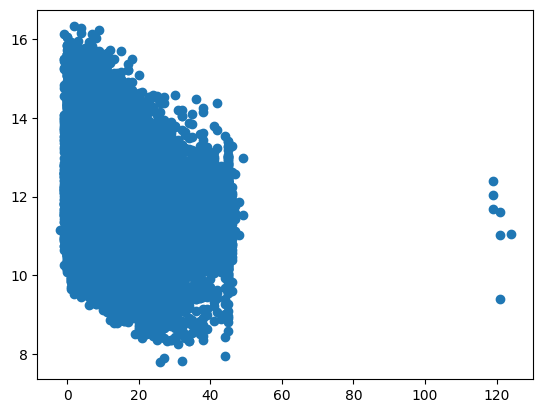

In [35]:
plt.scatter(sold_listings['age_at_sale'], sold_listings['log_usd_sale_price'])
plt.show()

From the plot we see that there's a general downward sloping trend.

<Axes: title={'center': 'log_usd_sale_price'}, xlabel='age_groups'>

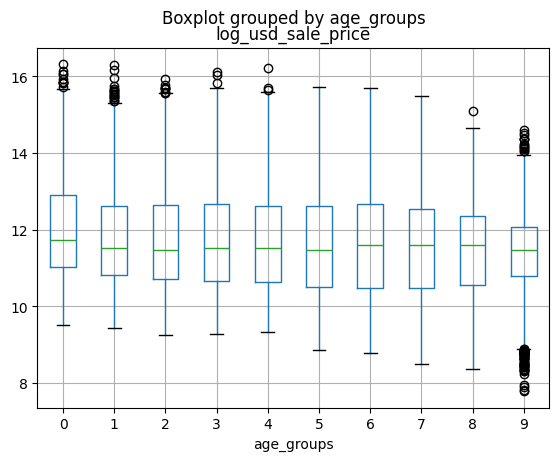

In [36]:
sold_listings['age_groups'] = pd.qcut(sold_listings['age_at_sale'], 10, labels=range(10))
sold_listings.boxplot('log_usd_sale_price', by='age_groups')

The average price has some difference in different age groups.

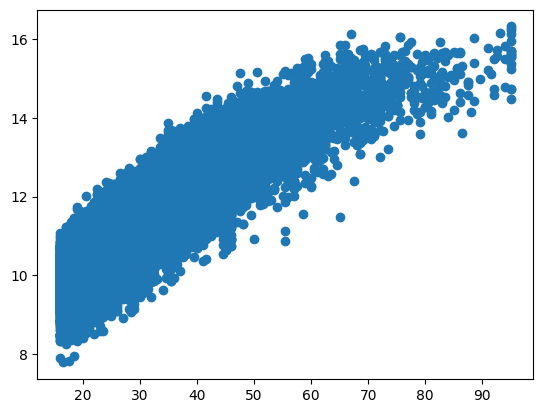

In [37]:
plt.scatter(sold_listings['length_ft'], sold_listings['log_usd_sale_price'])
plt.show()

<Axes: title={'center': 'log_usd_sale_price'}, xlabel='length_groups'>

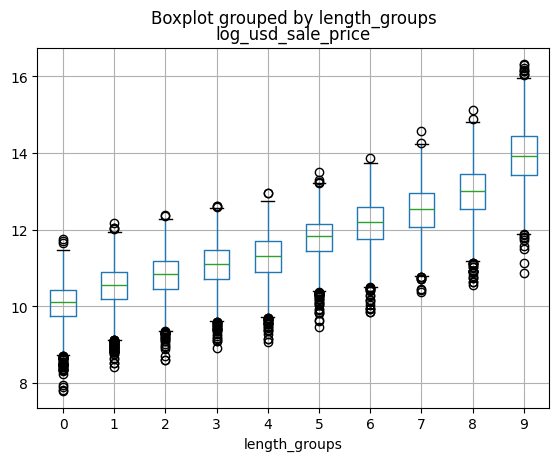

In [38]:
sold_listings['length_groups'] = pd.qcut(sold_listings['length_ft'], 10, labels=range(10))
sold_listings.boxplot('log_usd_sale_price', by='length_groups')

There is a monotonically increasing relationship between the log price and the length_groups.

In [39]:
# Pooled panel regression
valid_listings = sold_listings[(~sold_listings['age_at_sale'].isnull()) & (~sold_listings['length_ft'].isnull())]
model = sm.OLS(valid_listings['log_usd_sale_price'], sm.add_constant(valid_listings[['age_at_sale', 'length_ft']])).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     log_usd_sale_price   R-squared:                       0.859
Model:                            OLS   Adj. R-squared:                  0.859
Method:                 Least Squares   F-statistic:                 7.930e+04
Date:                Mon, 23 Nov 2026   Prob (F-statistic):               0.00
Time:                        21:19:42   Log-Likelihood:                -18218.
No. Observations:               25961   AIC:                         3.644e+04
Df Residuals:                   25958   BIC:                         3.647e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           8.9080      0.009    999.168      0.000       8.891       8.925
age_at_sale    -0.0365      0.000   -117.438      0.000      -0.037      -0.036
length_ft       0.0970      0.000    394.582      0.000       0.097       0.097
==============================================================================
Omnibus:                      891.706   Durbin-Watson:                   1.905
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2351.094
Skew:                          -0.126   Prob(JB):                         0.00
Kurtosis:                       4.453   Cond. No.                         110.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

The coefficient results align with what we expect from the plots. The age_years is a negative relationship and length_ft is a positive relationship.

In [40]:
sold_listings['boat_type'].value_counts()

boat_type
Sailboat             4714
Center Console       3925
Pontoon              3159
Bowrider             2865
Cabin Cruiser        2309
Sportfish            1294
Catamaran            1281
Motor Yacht          1257
Trawler              1161
Sail                  368
Centre Console        351
Bow Rider             309
sailboat              299
SAILBOAT              278
pontoon               268
center console        267
Pontoon Boat          263
CC                    239
Express Cruiser       215
bowrider              215
cabin cruiser         174
Sailing Catamaran     134
Sport Fisherman       123
motor yacht           108
sportfish             105
trawler               101
MY                     90
catamaran              89
Name: count, dtype: int64

In [41]:
type_mapping = {'Sail': 'Sailboat', 'Centre Console': 'Center Console', 'Bow Rider': 'Bowrider',
                'sailboat': 'Sailboat', 'SAILBOAT': 'Sailboat', 'pontoon': 'Pontoon', 'center console': 'Center Console',
                'Pontoon Boat': 'Pontoon', 'CC': 'Center Console', 'bowrider': 'Bowrider', 'cabin cruiser': 'Cabin Cruiser',
                'Sailing Catamaran': 'Catamaran', 'Sport Fisherman': 'Sportfish', 'motor yacht': 'Motor Yacht', 'sportfish': 'Sportfish',
                'trawler': 'Trawler', 'MY': 'Motor Yacht', 'catamaran': 'Catamaran'}
sold_listings['boat_type'] = sold_listings['boat_type'].map(lambda x: type_mapping[x] if x in type_mapping else x)
sold_listings['boat_type'].value_counts()

boat_type
Sailboat           5659
Center Console     4782
Pontoon            3690
Bowrider           3389
Cabin Cruiser      2483
Sportfish          1522
Catamaran          1504
Motor Yacht        1455
Trawler            1262
Express Cruiser     215
Name: count, dtype: int64

In [48]:
import statsmodels.formula.api as smf
valid_listings = sold_listings[(~sold_listings['age_at_sale'].isnull()) & (~sold_listings['length_ft'].isnull())]
model = smf.ols('log_usd_sale_price ~ age_at_sale + length_ft + C(boat_type) + age_at_sale:C(boat_type)', valid_listings).fit(cov_type='HC1')
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     log_usd_sale_price   R-squared:                       0.933
Model:                            OLS   Adj. R-squared:                  0.933
Method:                 Least Squares   F-statistic:                 1.550e+04
Date:                 周一, 23 11月 2026   Prob (F-statistic):               0.00
Time:                        21:32:05   Log-Likelihood:                -8496.9
No. Observations:               25961   AIC:                         1.704e+04
Df Residuals:                   25940   BIC:                         1.721e+04
Df Model:                          20                                         
Covariance Type:                  HC1                                         
===============================================================================================================
                                                  coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------
Intercept                                       9.5508      0.013    717.631      0.000       9.525       9.577
C(boat_type)[T.Cabin Cruiser]                   0.3235      0.050      6.494      0.000       0.226       0.421
C(boat_type)[T.Catamaran]                       1.0496      0.019     53.852      0.000       1.011       1.088
C(boat_type)[T.Center Console]                  0.3849      0.014     27.493      0.000       0.357       0.412
C(boat_type)[T.Express Cruiser]                 0.4085      0.043      9.564      0.000       0.325       0.492
C(boat_type)[T.Motor Yacht]                     1.1919      0.025     47.141      0.000       1.142       1.241
C(boat_type)[T.Pontoon]                        -0.2371      0.056     -4.221      0.000      -0.347      -0.127
C(boat_type)[T.Sailboat]                        0.5002      0.016     30.525      0.000       0.468       0.532
C(boat_type)[T.Sportfish]                       1.1005      0.022     51.178      0.000       1.058       1.143
C(boat_type)[T.Trawler]                         0.8917      0.023     38.361      0.000       0.846       0.937
age_at_sale                                    -0.0684      0.001    -66.563      0.000      -0.070      -0.066
age_at_sale:C(boat_type)[T.Cabin Cruiser]       0.0171      0.004      4.520      0.000       0.010       0.025
age_at_sale:C(boat_type)[T.Catamaran]           0.0301      0.002     18.182      0.000       0.027       0.033
age_at_sale:C(boat_type)[T.Center Console]      0.0104      0.001      7.502      0.000       0.008       0.013
age_at_sale:C(boat_type)[T.Express Cruiser]     0.0123      0.003      3.826      0.000       0.006       0.019
age_at_sale:C(boat_type)[T.Motor Yacht]         0.0099      0.002      5.349      0.000       0.006       0.014
age_at_sale:C(boat_type)[T.Pontoon]             0.0139      0.008      1.764      0.078      -0.002       0.029
age_at_sale:C(boat_type)[T.Sailboat]            0.0405      0.001     33.862      0.000       0.038       0.043
age_at_sale:C(boat_type)[T.Sportfish]           0.0112      0.002      6.988      0.000       0.008       0.014
age_at_sale:C(boat_type)[T.Trawler]             0.0292      0.002     17.831      0.000       0.026       0.032
length_ft                                       0.0685      0.000    184.147      0.000       0.068       0.069
==============================================================================
Omnibus:                     8144.996   Durbin-Watson:                   1.766
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           300444.220
Skew:                           0.834   Prob(JB):                         0.00
Kurtosis:                      19.582   Cond. No.                         765.


## A3

To measure the effect of time on price level, we can include a time fixed effect in the previous regression model.

In [48]:
sold_listings['region'].value_counts()

region
US-Florida       5774
US-Northeast     3887
US-GreatLakes    3214
EU-Med           3168
US-West          3121
UK               2631
US-Gulf          2391
EU-North         2191
Name: count, dtype: int64

In [ ]:


model = smf.ols('log_usd_sale_price ~ age_at_sale + length_ft + beam_ft + engine_hours + C(year) + C(condition) + C(boat_type) + C(region)', valid_listings, ).fit(cov_type='HC1')
model.summary()

c:\Users\20122\anaconda3\Lib\site-packages\statsmodels\base\model.py:130: ValueWarning: unknown kwargs ['cov_type']
  warnings.warn(msg, ValueWarning)


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     log_usd_sale_price   R-squared:                       0.955
Model:                            OLS   Adj. R-squared:                  0.955
Method:                 Least Squares   F-statistic:                     8200.
Date:                 周一, 23 11月 2026   Prob (F-statistic):               0.00
Time:                        20:40:13   Log-Likelihood:                -2550.0
No. Observations:               18275   AIC:                             5196.
Df Residuals:                   18227   BIC:                             5571.
Df Model:                          47                                         
Covariance Type:            nonrobust                                         
=====================================================================================================
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                             9.3418      0.022    428.854      0.000       9.299       9.385
C(year)[T.2020]                       0.0606      0.007      8.602      0.000       0.047       0.074
C(year)[T.2021]                       0.2806      0.007     40.296      0.000       0.267       0.294
C(year)[T.2022]                       0.2810      0.007     39.944      0.000       0.267       0.295
C(year)[T.2023]                       0.1953      0.007     27.541      0.000       0.181       0.209
C(year)[T.2024]                       0.1642      0.008     21.602      0.000       0.149       0.179
C(condition)[T.fair]                 -0.3952      0.006    -67.465      0.000      -0.407      -0.384
C(condition)[T.good]                 -0.2199      0.005    -42.089      0.000      -0.230      -0.210
C(condition)[T.new]                8.819e-05      0.012      0.008      0.994      -0.023       0.023
C(condition)[T.project]              -0.5805      0.008    -68.325      0.000      -0.597      -0.564
C(boat_type)[T.Bowrider]              0.0061      0.020      0.302      0.762      -0.033       0.045
C(boat_type)[T.CC]                    0.5439      0.028     19.200      0.000       0.488       0.599
C(boat_type)[T.Cabin Cruiser]         0.4800      0.021     23.278      0.000       0.440       0.520
C(boat_type)[T.Catamaran]             1.5529      0.036     43.345      0.000       1.483       1.623
C(boat_type)[T.Center Console]        0.5388      0.020     27.144      0.000       0.500       0.578
C(boat_type)[T.Centre Console]        0.5413      0.026     20.850      0.000       0.490       0.592
C(boat_type)[T.Express Cruiser]       0.4845      0.030     16.326      0.000       0.426       0.543
C(boat_type)[T.MY]                    1.3058      0.042     31.371      0.000       1.224       1.387
C(boat_type)[T.Motor Yacht]           1.3561      0.024     56.268      0.000       1.309       1.403
C(boat_type)[T.Pontoon]              -0.0488      0.020     -2.431      0.015      -0.088      -0.009
C(boat_type)[T.Pontoon Boat]         -0.0403      0.028     -1.450      0.147      -0.095       0.014
C(boat_type)[T.SAILBOAT]              0.9733      0.028     34.340      0.000       0.918       1.029
C(boat_type)[T.Sail]                  1.0129      0.026     38.285      0.000       0.961       1.065
C(boat_type)[T.Sailboat]              1.0016      0.020     49.299      0.000       0.962       1.041
C(boat_type)[T.Sailing Catamaran]     1.5785      0.044     35.794      0.000       1.492       1.665
C(boat_type)[T.Sport Fisherman]       1.3091      0.035     37.838      0.000       1.241       1.377
C(boat_type)[T.Sportfish]             1.2959      0.023     57.060      0.000       1.251       1.340
C(boat_type)[T.Trawler]

In [51]:
sold_listings.groupby('year')['log_usd_sale_price'].median()

year
2019    11.455828
2020    11.432799
2021    11.497974
2022    11.648330
2023    11.623401
2024    11.674194
Name: log_usd_sale_price, dtype: float64

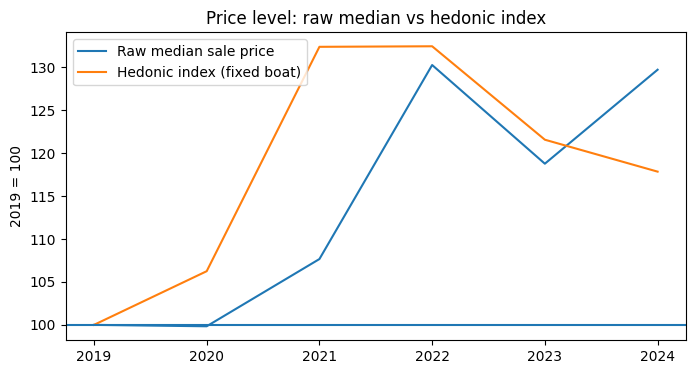

In [57]:
# use exactly the rows the regression used, so the two lines differ only by composition
used = valid_listings.loc[model.model.data.row_labels]
years = sorted(used['year'].unique())
base = 2019
yr = [f'C(year)[T.{y}]' for y in years[1:]]

delta = pd.Series([0.0] + list(model.params[yr]), index=years)

med = used.groupby('year')['log_usd_sale_price'].median()
med = med - med[base]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(years, 100 * np.exp(med), label='Raw median sale price')
ax.plot(years, 100 * np.exp(delta), label='Hedonic index (fixed boat)')
ax.axhline(100)
ax.set_ylabel(f'{base} = 100')
ax.set_title('Price level: raw median vs hedonic index')
ax.legend()
plt.show()

A simple median sale price mixes the effects of different entities in their characteristics, while the regression method measure the effects of time after controlling the individual factors.

# B

In [ ]:
def yearly_splits(df, start, end):
    for y in range(start, end+1):
        test  = (df['year'] >= y) & (df['year'] < y + 1)
        train = (df['year'] < y)
        yield y, train, test

def walk_forward(df, features, make_model, target, **split_kw):
    out = []
    for y, tr, te in yearly_splits(df, **split_kw):
        model = make_model().fit(df.loc[tr, features], df.loc[tr, target])
        pred = df.loc[te, ['date', 'year', 'log_usd_sale_price']].copy()
        pred['pred_usd_price'] = np.exp(model.predict(df.loc[te, features]))
        out.append(pred)
    return pd.concat(out)